# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Rio Andika Andriansyah
- **Email:** andikario0101@gmail.com
- **ID Dicoding:** rioandikaa01

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

### Daftar Pertanyaan Bisnis

**Pertanyaan 1 (Temporal Analysis):**
Bagaimana pola rata-rata jumlah penyewaan sepeda harian berdasarkan bulan dan musim selama periode 2011–2012, serta pada bulan dan musim mana jumlah penyewaan mencapai nilai tertinggi dan terendah?

- **Specific:** Fokus pada "rata-rata penyewaan harian" yang dikelompokkan per bulan dan per musim.
- **Measurable:** Metrik yang diukur adalah rata-rata `cnt` (total penyewaan), dapat dibandingkan antar bulan/musim.
- **Action-Oriented:** Hasilnya dapat digunakan untuk merencanakan strategi operasional (penambahan armada, promo) di bulan/musim puncak.
- **Relevant:** Pemahaman tren musiman sangat kritis bagi bisnis bike sharing untuk optimasi sumber daya.
- **Time-bound:** Dibatasi pada periode 2011–2012 (data yang tersedia di dataset).

---

**Pertanyaan 2 (User Behavior Analysis):**
Bagaimana perbedaan pola rata-rata jumlah penyewaan sepeda per jam antara hari kerja (working day) dan hari non-kerja (weekend/holiday) selama periode 2011–2012, khususnya pada jam-jam berapa puncak penyewaan terjadi di masing-masing tipe hari?

- **Specific:** Fokus pada pola per jam, dibedakan antara hari kerja dan hari non-kerja.
- **Measurable:** Metrik yang diukur adalah rata-rata `cnt` per jam untuk dua kelompok hari.
- **Action-Oriented:** Mengetahui jam puncak memungkinkan tim operasional untuk mengatur distribusi sepeda secara tepat waktu.
- **Relevant:** Pola penggunaan per jam membantu meningkatkan ketersediaan armada dan kepuasan pengguna.
- **Time-bound:** Dibatasi pada periode 2011–2012.

---

**Pertanyaan 3 (Weather Impact Analysis):**
Bagaimana pengaruh kondisi cuaca (weathersit), suhu (temp), dan kelembapan (hum) terhadap rata-rata jumlah penyewaan sepeda harian selama periode 2011–2012?

- **Specific:** Fokus pada tiga faktor cuaca spesifik terhadap jumlah penyewaan harian.
- **Measurable:** Metrik yang diukur adalah rata-rata `cnt` per kategori cuaca dan korelasi numerik dengan temp/hum.
- **Action-Oriented:** Hasilnya dapat digunakan untuk membuat sistem prediksi permintaan berbasis cuaca.
- **Relevant:** Cuaca adalah faktor eksternal paling signifikan yang memengaruhi keputusan bersepeda.
- **Time-bound:** Dibatasi pada periode 2011–2012.

## Import Semua Packages/Library yang Digunakan

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 11


## Data Wrangling

### Gathering Data

Pada tahap ini, kita akan memuat dataset Bike Sharing yang terdiri dari dua file:
- `day.csv`: Data agregat harian penyewaan sepeda (731 baris)
- `hour.csv`: Data per jam penyewaan sepeda (17.379 baris)

#### Load day_df

In [2]:
day_df = pd.read_csv("datasets/day.csv")

print(f"Shape day_df: {day_df.shape}")
print(f"Kolom: {list(day_df.columns)}")
day_df.head()

Shape day_df: (731, 16)
Kolom: ['instant', 'dteday', 'season', 'yr', 'mnth', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


**Insight:**



- Dataset `day_df` berisi **731 baris** dan **16 kolom**, mencakup data lengkap selama **2 tahun penuh** (1 Januari 2011 – 31 Desember 2012). Rentang waktu ini cukup untuk mengidentifikasi pola musiman tahunan dan pertumbuhan tahun ke tahun.

- Kolom utama yang relevan untuk analisis: `dteday` (tanggal), `season` (musim), `mnth` (bulan), `yr` (tahun), `weathersit` (kondisi cuaca), `temp`/`atemp` (suhu), `hum` (kelembapan), `windspeed` (kecepatan angin), `casual` (pengguna casual), `registered` (pengguna terdaftar), dan `cnt` (total penyewaan).

- Kolom `dteday` saat ini bertipe `object` (string), perlu dikonversi ke `datetime64` agar dapat dilakukan analisis time-series (pola bulanan, musiman, dan pertumbuhan tahunan).

- Nilai numerik (`temp`, `atemp`, `hum`, `windspeed`) tersimpan dalam skala **normalized (0–1)** sesuai dokumentasi dataset, sehingga perlu dikonversi kembali ke satuan asli (Celsius, persen, km/h) untuk interpretasi yang lebih mudah bagi stakeholder bisnis.



#### Load hour_df

In [3]:
hour_df = pd.read_csv("datasets/hour.csv")

print(f"Shape hour_df: {hour_df.shape}")
print(f"Kolom: {list(hour_df.columns)}")
hour_df.head()

Shape hour_df: (17379, 17)
Kolom: ['instant', 'dteday', 'season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight:**



- Dataset `hour_df` berisi **17.379 baris** dan **17 kolom** — sama seperti `day_df` ditambah kolom `hr` (jam 0–23). Dengan granularitas per jam, dataset ini sekitar **24× lebih detail** dari `day_df`.

- Kolom `dteday` juga bertipe `object`, perlu dikonversi ke `datetime64` untuk analisis berbasis waktu.

- Dataset ini sangat cocok untuk analisis **pola penyewaan per jam**, identifikasi **jam puncak (peak hours)**, dan perbandingan perilaku antara **hari kerja vs hari non-kerja** — insight yang langsung relevan untuk pengaturan redistribusi armada dan operasional stasiun sepeda.

- `hour_df` melengkapi `day_df`: sementara `day_df` digunakan untuk analisis musiman dan tahunan, `hour_df` digunakan untuk analisis intra-harian dan perilaku pengguna berdasarkan waktu dalam sehari.



### Assessing Data

Pada tahap ini, kita akan menilai kualitas data dari kedua dataset untuk mengidentifikasi permasalahan yang perlu ditangani sebelum analisis dilakukan.

#### Identifying day_df Problems

In [4]:
print("=" * 60)
print("1. INFO TIPE DATA & MISSING VALUES - day_df")
print("=" * 60)
day_df.info()

print("\n" + "=" * 60)
print("2. JUMLAH MISSING VALUES - day_df")
print("=" * 60)
print(day_df.isnull().sum())

print("\n" + "=" * 60)
print("3. JUMLAH DUPLIKAT BARIS - day_df")
print("=" * 60)
print(f"Jumlah baris duplikat: {day_df.duplicated().sum()}")

1. INFO TIPE DATA & MISSING VALUES - day_df
<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    str    
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), str(1)
memory usage: 98.6 KB

2. JUMLAH MISSING VALUES - day_df
instant       0
dteday       

In [5]:
print("=" * 60)
print("4. STATISTIK DESKRIPTIF - day_df")
print("=" * 60)
day_df.describe(include="all").T

4. STATISTIK DESKRIPTIF - day_df


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
instant,731.0,NaN,NaN,NaN,366.0,211.165812,1.0,183.5,366.0,548.5,731.0
dteday,731,731,2011-01-01,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
season,731.0,NaN,NaN,NaN,2.49658,1.110807,1.0,2.0,3.0,3.0,4.0
yr,731.0,NaN,NaN,NaN,0.500684,0.500342,0.0,0.0,1.0,1.0,1.0
mnth,731.0,NaN,NaN,NaN,6.519836,3.451913,1.0,4.0,7.0,10.0,12.0
holiday,731.0,NaN,NaN,NaN,0.028728,0.167155,0.0,0.0,0.0,0.0,1.0
weekday,731.0,NaN,NaN,NaN,2.997264,2.004787,0.0,1.0,3.0,5.0,6.0
workingday,731.0,NaN,NaN,NaN,0.683995,0.465233,0.0,0.0,1.0,1.0,1.0
weathersit,731.0,NaN,NaN,NaN,1.395349,0.544894,1.0,1.0,1.0,2.0,3.0
temp,731.0,NaN,NaN,NaN,0.495385,0.183051,0.05913,0.337083,0.498333,0.655417,0.861667


In [6]:
print("=" * 60)
print("5. PENGECEKAN NILAI TIDAK VALID - day_df")
print("=" * 60)

print(f"Nilai unik season  : {sorted(day_df['season'].unique())}  -> Valid: 1-4")

print(f"Nilai unik weathersit: {sorted(day_df['weathersit'].unique())}  -> Valid: 1-4")

print(f"Nilai unik yr      : {sorted(day_df['yr'].unique())}  -> Valid: 0 or 1")

print(f"Nilai unik holiday : {sorted(day_df['holiday'].unique())}  -> Valid: 0 or 1")

print(f"Nilai unik workingday: {sorted(day_df['workingday'].unique())}  -> Valid: 0 or 1")

print(f"hum min={day_df['hum'].min():.4f}, max={day_df['hum'].max():.4f}  -> Expected: 0–1")

Q1 = day_df['cnt'].quantile(0.25)
Q3 = day_df['cnt'].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
outliers = day_df[(day_df['cnt'] < lower) | (day_df['cnt'] > upper)]
print(f"\nOutlier cnt (IQR method): {len(outliers)} baris  (lower={lower:.0f}, upper={upper:.0f})")

print(f"\nTipe data 'dteday': {day_df['dteday'].dtype}  -> Seharusnya datetime64")

5. PENGECEKAN NILAI TIDAK VALID - day_df
Nilai unik season  : [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]  -> Valid: 1-4
Nilai unik weathersit: [np.int64(1), np.int64(2), np.int64(3)]  -> Valid: 1-4
Nilai unik yr      : [np.int64(0), np.int64(1)]  -> Valid: 0 or 1
Nilai unik holiday : [np.int64(0), np.int64(1)]  -> Valid: 0 or 1
Nilai unik workingday: [np.int64(0), np.int64(1)]  -> Valid: 0 or 1
hum min=0.0000, max=0.9725  -> Expected: 0–1

Outlier cnt (IQR method): 0 baris  (lower=-1054, upper=10162)

Tipe data 'dteday': str  -> Seharusnya datetime64


**Permasalahan yang Ditemukan pada `day_df`:**

| No | Permasalahan | Detail | Dampak Bisnis | Solusi |
|:--:|:---|:---|:---|:---|
| **1** | **Tipe data tidak sesuai** | Kolom `dteday` bertipe `object` (string), bukan `datetime64` | Tidak dapat dilakukan analisis *time-series*, pengelompokan (*grouping*) bulanan/musiman, atau kalkulasi rentang waktu | Konversi ke `datetime64` menggunakan `pd.to_datetime()` |
| **2** | **Kolom kategorik berupa integer** | Kolom `season`, `mnth`, `weathersit`, `holiday`, `workingday`, `weekday`, `yr` tersimpan sebagai `int64` | Sulit dibaca dan dipahami stakeholder secara intuitif saat visualisasi (misal: kode angka `season=1` tidak langsung jelas mewakili musim apa) | Lakukan pemetaan nilai (*value mapping*) menjadi label teks yang deskriptif |
| **3** | **Nilai `hum = 0` (Anomali)** | Ditemukan nilai kelembapan bernilai 0% yang secara fisik lingkungan tidak realistis | Berpotensi mendistorsi analisis korelasi kelembapan terhadap jumlah penyewaan (*bias*) | Verifikasi, dokumentasikan sebagai anomali data sensor, dan pertimbangkan evaluasi/pengecualian jika diperlukan |

**Insight dari Assessing Data:**

- **Kelengkapan Data:** Tidak ditemukan adanya *missing values* (nilai kosong) maupun baris duplikat pada `day_df` — seluruh 731 baris data utuh dan lengkap.
- **Konsistensi Logis:** Nilai `casual + registered == cnt` terpenuhi secara matematis di seluruh baris tanpa ada kejanggalan pencatatan.
- **Skala Numerik:** Seluruh variabel lingkungan cuaca (`temp`, `atemp`, `hum`, `windspeed`) berada dalam skala ternormalisasi (0–1) sesuai standar teknis dataset, namun memerlukan konversi ke satuan fisik riil (°C, %, km/jam) agar mudah dipahami dalam pengambilan keputusan bisnis.
- **Fokus Pembersihan (*Data Cleaning*):** Prioritas utama terletak pada **konversi tipe data `dteday`** serta **pembuatan kolom label kategorik** agar proses agregasi EDA dan visualisasi dapat dijalankan secara akurat dan mudah diinterpretasikan.



#### Identifying hour_df Problems

In [7]:
print("=" * 60)
print("1. INFO TIPE DATA & MISSING VALUES - hour_df")
print("=" * 60)
hour_df.info()

print("\n" + "=" * 60)
print("2. JUMLAH MISSING VALUES - hour_df")
print("=" * 60)
print(hour_df.isnull().sum())

print("\n" + "=" * 60)
print("3. JUMLAH DUPLIKAT BARIS - hour_df")
print("=" * 60)
print(f"Jumlah baris duplikat: {hour_df.duplicated().sum()}")

1. INFO TIPE DATA & MISSING VALUES - hour_df
<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  str    
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), str(1)
memory usage: 2.4 MB

2. JUMLAH MISSING 

instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

3. JUMLAH DUPLIKAT BARIS - hour_df
Jumlah baris duplikat: 0


In [8]:
print("=" * 60)
print("4. PENGECEKAN NILAI TIDAK VALID - hour_df")
print("=" * 60)

print(f"Nilai unik hr: min={hour_df['hr'].min()}, max={hour_df['hr'].max()}  -> Valid: 0-23")

print(f"hum min={hour_df['hum'].min():.4f}, max={hour_df['hum'].max():.4f}  -> Expected: 0–1")
zero_hum = hour_df[hour_df['hum'] == 0]
print(f"Baris dengan hum=0: {len(zero_hum)}")

print(f"windspeed min={hour_df['windspeed'].min():.4f}, max={hour_df['windspeed'].max():.4f}")

print(f"casual < 0: {(hour_df['casual'] < 0).sum()} baris")
print(f"registered < 0: {(hour_df['registered'] < 0).sum()} baris")

inconsistent = hour_df[hour_df['casual'] + hour_df['registered'] != hour_df['cnt']]
print(f"\nBaris tidak konsisten (casual+registered != cnt): {len(inconsistent)}")

print(f"\nTipe data 'dteday': {hour_df['dteday'].dtype}  -> Seharusnya datetime64")

4. PENGECEKAN NILAI TIDAK VALID - hour_df
Nilai unik hr: min=0, max=23  -> Valid: 0-23
hum min=0.0000, max=1.0000  -> Expected: 0–1
Baris dengan hum=0: 22
windspeed min=0.0000, max=0.8507
casual < 0: 0 baris
registered < 0: 0 baris

Baris tidak konsisten (casual+registered != cnt): 0

Tipe data 'dteday': str  -> Seharusnya datetime64


**Permasalahan yang Ditemukan pada `hour_df`:**

| No | Permasalahan | Detail | Dampak Bisnis | Solusi |
|:--:|:---|:---|:---|:---|
| **1** | **Tipe data tidak sesuai** | Kolom `dteday` bertipe `object` (string), bukan `datetime64` | Tidak dapat dilakukan integrasi time-series, pengelompokan (*grouping*) berbasis tanggal, atau sinkronisasi dengan dataset harian | Konversi ke `datetime64` menggunakan `pd.to_datetime()` |
| **2** | **Kolom kategorik berupa integer** | Kolom `season`, `mnth`, `weathersit`, `holiday`, `workingday`, `weekday`, `yr` tersimpan sebagai `int64` | Menyulitkan interpretasi grafis dan pelaporan bagi stakeholder non-teknis saat membaca pola intra-harian | Lakukan pemetaan nilai (*value mapping*) menjadi label teks yang deskriptif dan bermakna |
| **3** | **Nilai `hum = 0` (Anomali)** | Ditemukan beberapa baris data per jam dengan nilai kelembapan udara 0% | Berpotensi mendistorsi kalkulasi statistik korelasi cuaca terhadap fluktuasi sewa per jam (*noise/bias*) | Verifikasi, catat sebagai anomali pembacaan sensor, dan evaluasi dampak statistiknya |

**Insight dari Assessing Data:**

- **Integritas Baris Data:** Tidak ditemukan adanya *missing values* (nilai kosong) maupun baris duplikat pada `hour_df` — seluruh **17.379 baris data per jam** tercatat secara lengkap dan utuh.
- **Konsistensi Logis & Validitas Agregasi:** Persamaan `casual + registered == cnt` terpenuhi secara matematis pada **seluruh 17.379 baris**, membuktikan bahwa tidak ada inkonsistensi pencatatan transaksi sewa per jam.
- **Granularitas Tinggi:** Dengan data tingkat per jam (`hr` 0–23), dataset ini sangat ideal untuk mendeteksi dinamika jam sibuk komuter (*rush hour*) serta perbedaan perilaku antara pengguna *casual* dan *registered*.
- **Fokus Pembersihan (*Data Cleaning*):** Menyelaraskan skema tipe data `dteday` dan label kategorik agar konsisten dengan `day_df`, serta mengonversi variabel cuaca ke skala riil (°C, %, km/jam) untuk kebutuhan analisis jam sibuk.


### Cleaning Data

Berdasarkan hasil assessing data, kita akan melakukan pembersihan data berikut:
1. Konversi tipe data kolom `dteday` ke `datetime64`
2. Pemetaan nilai numerik pada kolom kategorik menjadi label yang bermakna
3. Verifikasi dan penanganan nilai hum = 0

#### Fix 1: Konversi Tipe Data dteday ke datetime

In [9]:
day_df['dteday'] = pd.to_datetime(day_df['dteday'])
hour_df['dteday'] = pd.to_datetime(hour_df['dteday'])

print(f"Tipe dteday day_df  : {day_df['dteday'].dtype}")
print(f"Tipe dteday hour_df : {hour_df['dteday'].dtype}")
print(f"Rentang tanggal day_df  : {day_df['dteday'].min()} s.d. {day_df['dteday'].max()}")
print(f"Rentang tanggal hour_df : {hour_df['dteday'].min()} s.d. {hour_df['dteday'].max()}")

Tipe dteday day_df  : datetime64[us]
Tipe dteday hour_df : datetime64[us]
Rentang tanggal day_df  : 2011-01-01 00:00:00 s.d. 2012-12-31 00:00:00
Rentang tanggal hour_df : 2011-01-01 00:00:00 s.d. 2012-12-31 00:00:00


#### Fix 2: Pemetaan Label Kolom Kategorik

In [10]:
season_map    = {1: 'Spring', 2: 'Summer', 3: 'Fall', 4: 'Winter'}
yr_map        = {0: '2011', 1: '2012'}
month_map     = {1: 'Jan', 2: 'Feb', 3: 'Mar', 4: 'Apr', 5: 'May', 6: 'Jun',
                 7: 'Jul', 8: 'Aug', 9: 'Sep', 10: 'Oct', 11: 'Nov', 12: 'Dec'}
weekday_map   = {0: 'Sun', 1: 'Mon', 2: 'Tue', 3: 'Wed', 4: 'Thu', 5: 'Fri', 6: 'Sat'}
weather_map   = {
    1: 'Clear/Partly Cloudy',
    2: 'Mist/Cloudy',
    3: 'Light Snow/Rain',
    4: 'Heavy Rain/Snow'
}
holiday_map   = {0: 'No', 1: 'Yes'}
working_map   = {0: 'No', 1: 'Yes'}

day_df['season_label']     = day_df['season'].map(season_map)
day_df['yr_label']         = day_df['yr'].map(yr_map)
day_df['mnth_label']       = day_df['mnth'].map(month_map)
day_df['weekday_label']    = day_df['weekday'].map(weekday_map)
day_df['weather_label']    = day_df['weathersit'].map(weather_map)
day_df['holiday_label']    = day_df['holiday'].map(holiday_map)
day_df['workingday_label'] = day_df['workingday'].map(working_map)

hour_df['season_label']     = hour_df['season'].map(season_map)
hour_df['yr_label']         = hour_df['yr'].map(yr_map)
hour_df['mnth_label']       = hour_df['mnth'].map(month_map)
hour_df['weekday_label']    = hour_df['weekday'].map(weekday_map)
hour_df['weather_label']    = hour_df['weathersit'].map(weather_map)
hour_df['holiday_label']    = hour_df['holiday'].map(holiday_map)
hour_df['workingday_label'] = hour_df['workingday'].map(working_map)

print("Kolom label berhasil ditambahkan!")
print(f"\nContoh season_label day_df: {day_df['season_label'].unique()}")
print(f"Contoh weather_label day_df: {day_df['weather_label'].unique()}")

Kolom label berhasil ditambahkan!

Contoh season_label day_df: <ArrowStringArray>
['Spring', 'Summer', 'Fall', 'Winter']
Length: 4, dtype: str
Contoh weather_label day_df: <ArrowStringArray>
['Mist/Cloudy', 'Clear/Partly Cloudy', 'Light Snow/Rain']
Length: 3, dtype: str


#### Fix 3: Konversi Skala Suhu ke Celsius

In [11]:
day_df['temp_celsius']  = day_df['temp'] * 41
day_df['atemp_celsius'] = day_df['atemp'] * 50
day_df['hum_pct']       = day_df['hum'] * 100  # persen
day_df['wind_ms']       = day_df['windspeed'] * 67  # km/h (approx)

hour_df['temp_celsius']  = hour_df['temp'] * 41
hour_df['atemp_celsius'] = hour_df['atemp'] * 50
hour_df['hum_pct']       = hour_df['hum'] * 100
hour_df['wind_ms']       = hour_df['windspeed'] * 67

print("Konversi skala berhasil!")
print(f"Rentang suhu (day_df): {day_df['temp_celsius'].min():.1f}°C – {day_df['temp_celsius'].max():.1f}°C")
print(f"Rata-rata suhu (day_df): {day_df['temp_celsius'].mean():.1f}°C")

Konversi skala berhasil!
Rentang suhu (day_df): 2.4°C – 35.3°C
Rata-rata suhu (day_df): 20.3°C


#### Verifikasi Data Setelah Cleaning

In [12]:
print("=" * 60)
print("VERIFIKASI AKHIR - day_df")
print("=" * 60)
print(f"Shape  : {day_df.shape}")
print(f"Missing: {day_df.isnull().sum().sum()}")
print(f"Duplikat: {day_df.duplicated().sum()}")
day_df.head(3)


VERIFIKASI AKHIR - day_df
Shape  : (731, 27)
Missing: 0


Duplikat: 0


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,...,yr_label,mnth_label,weekday_label,weather_label,holiday_label,workingday_label,temp_celsius,atemp_celsius,hum_pct,wind_ms
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,...,2011,Jan,Sat,Mist/Cloudy,No,No,14.110847,18.18125,80.5833,10.749882
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,...,2011,Jan,Sun,Mist/Cloudy,No,No,14.902598,17.68695,69.6087,16.652113
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,...,2011,Jan,Mon,Clear/Partly Cloudy,No,Yes,8.050924,9.47025,43.7273,16.636703


In [13]:
print("=" * 60)
print("VERIFIKASI AKHIR - hour_df")
print("=" * 60)
print(f"Shape  : {hour_df.shape}")
print(f"Missing: {hour_df.isnull().sum().sum()}")
print(f"Duplikat: {hour_df.duplicated().sum()}")
hour_df.head(3)

VERIFIKASI AKHIR - hour_df
Shape  : (17379, 28)
Missing: 0
Duplikat: 0


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,...,yr_label,mnth_label,weekday_label,weather_label,holiday_label,workingday_label,temp_celsius,atemp_celsius,hum_pct,wind_ms
0,1,2011-01-01,1,0,1,0,0,6,0,1,...,2011,Jan,Sat,Clear/Partly Cloudy,No,No,9.84,14.395,81.0,0.0
1,2,2011-01-01,1,0,1,1,0,6,0,1,...,2011,Jan,Sat,Clear/Partly Cloudy,No,No,9.02,13.635,80.0,0.0
2,3,2011-01-01,1,0,1,2,0,6,0,1,...,2011,Jan,Sat,Clear/Partly Cloudy,No,No,9.02,13.635,80.0,0.0


In [14]:
os.makedirs('dashboard', exist_ok=True)

day_df.to_csv('dashboard/day_data.csv', index=False)

hour_df.to_csv('dashboard/hour_data.csv', index=False)

print("Data cleaned telah disimpan ke folder dashboard:")
print("  - dashboard/day_data.csv: {} baris, {} kolom".format(day_df.shape[0], day_df.shape[1]))
print("  - dashboard/hour_data.csv: {} baris, {} kolom".format(hour_df.shape[0], hour_df.shape[1]))


Data cleaned telah disimpan ke folder dashboard:
  - dashboard/day_data.csv: 731 baris, 27 kolom
  - dashboard/hour_data.csv: 17379 baris, 28 kolom


**Insight setelah Cleaning Data:**



- Kedua dataset kini memiliki **tipe data yang benar** untuk semua kolom, terutama `dteday` yang sudah dalam format `datetime64` — siap untuk analisis time-series dan grouping berdasarkan waktu.

- Kolom label kategorik telah ditambahkan (`season_label`, `yr_label`, `mnth_label`, `weather_label`, `workingday_label`, `weekday_label`) sehingga visualisasi dan interpretasi hasil analisis akan lebih mudah dipahami oleh stakeholder bisnis.

- Kolom suhu (`temp_celsius`, `atemp_celsius`), kelembapan (`hum_pct`), dan kecepatan angin (`wind_ms`) telah dikonversi dari skala normalized (0–1) ke satuan asli yang interpretatif (Celsius, persen, km/h).

- Data telah diverifikasi: **tidak ada missing value**, **tidak ada baris duplikat**, dan semua kolom kunci sudah dalam format yang benar — **data bersih dan siap digunakan untuk tahap Exploratory Data Analysis (EDA)**.



## Exploratory Data Analysis (EDA)

### EDA 1: Temporal Analysis — Pola Penyewaan per Bulan dan Musim (2011–2012)

In [15]:
monthly_avg = (
    day_df.groupby(['yr_label', 'mnth', 'mnth_label'])['cnt']
    .mean()
    .reset_index()
    .sort_values('mnth')
)

print("=" * 60)
print("Rata-rata penyewaan harian per bulan (2011–2012)")
print("=" * 60)
monthly_pivot = monthly_avg.pivot(index='mnth_label', columns='yr_label', values='cnt').reindex(
    ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
)
print(monthly_pivot.round(0).to_string())

Rata-rata penyewaan harian per bulan (2011–2012)
yr_label      2011    2012
mnth_label                
Jan         1232.0  3121.0
Feb         1722.0  3556.0
Mar         2066.0  5319.0
Apr         3162.0  5807.0
May         4381.0  6318.0
Jun         4784.0  6761.0
Jul         4559.0  6568.0
Aug         4409.0  6919.0
Sep         4247.0  7286.0
Oct         3984.0  6414.0
Nov         3406.0  5089.0
Dec         2817.0  3991.0


In [16]:
season_order = ['Spring', 'Summer', 'Fall', 'Winter']

season_avg = (
    day_df.groupby('season_label')['cnt']
    .agg(['mean', 'median', 'std', 'min', 'max'])
    .loc[season_order]
    .round(0)
)

print("=" * 60)
print("Statistik penyewaan per musim (2011–2012 gabungan)")
print("=" * 60)
print(season_avg.to_string())

Statistik penyewaan per musim (2011–2012 gabungan)
                mean  median     std   min   max
season_label                                    
Spring        2604.0  2209.0  1400.0   431  7836
Summer        4992.0  4942.0  1696.0   795  8362
Fall          5644.0  5354.0  1460.0  1115  8714
Winter        4728.0  4634.0  1700.0    22  8555


In [17]:
yearly_summary = day_df.groupby('yr_label')['cnt'].agg(['sum', 'mean', 'median']).round(0)
print("=" * 60)
print("Ringkasan per tahun")
print("=" * 60)
print(yearly_summary)
growth = (yearly_summary.loc['2012','sum'] - yearly_summary.loc['2011','sum']) / yearly_summary.loc['2011','sum'] * 100
print(f"\nPertumbuhan total penyewaan 2011→2012: +{growth:.1f}%")

Ringkasan per tahun
              sum    mean  median
yr_label                         
2011      1243103  3406.0  3740.0
2012      2049576  5600.0  5927.0

Pertumbuhan total penyewaan 2011→2012: +64.9%


**Insight EDA 1 — Analisis Temporal (Pola Bulanan dan Musiman):**



- **Fluktuasi Musiman yang Konsisten:**
  - Aktivitas penyewaan mencapai puncak tertingginya pada musim **Fall (Gugur)** dengan rata-rata **5.644 sepeda/hari** (puncak tertinggi mencapai 8.714), diikuti oleh musim **Summer (Panas)** sebesar **4.992 sepeda/hari** dan **Winter (Dingin)** sebesar **4.728 sepeda/hari**.
  - Musim **Spring (Semi)** mencatatkan rata-rata terendah dengan hanya **2.604 sepeda/hari** — terjadi penurunan lebih dari **53%** dibandingkan musim Fall.

- **Pola Tren Bulanan (Januari vs Puncak Musim Panas/Gugur):**
  - Rata-rata penyewaan harian terendah secara konsisten terjadi di **bulan Januari** (1.232 sepeda/hari pada 2011 dan 3.121 sepeda/hari pada 2012).
  - Permintaan meningkat drastis memasuki pertengahan tahun hingga puncaknya di bulan **Juni pada 2011** (4.784 sepeda/hari) dan bulan **September pada 2012** (7.286 sepeda/hari).

- **Pertumbuhan Bisnis yang Signifikan (YoY Growth):**
  - Terdapat lonjakan total volume penyewaan sebesar **+64,9%** dari tahun 2011 (1.243.103 transaksi) ke tahun 2012 (2.049.576 transaksi).
  - Rata-rata harian meningkat signifikan dari **3.406 menjadi 5.600 sepeda/hari**, mengindikasikan adopsi layanan yang bertumbuh sangat pesat.

- **Implikasi Bisnis:**
  - **Skalabilitas Armada & Distribusi:** Perusahaan perlu memaksimalkan ketersediaan armada dan frekuensi redistribusi sepeda antar-stasiun pada periode puncak (**Mei–Oktober / Summer–Fall**).
  - **Jadwal Perawatan (Maintenance):** Periode low-demand pada **Desember–Februari (terutama Januari)** adalah waktu paling ideal untuk melakukan perawatan besar (*overhaul*), perbaikan berkala, dan evaluasi unit armada tanpa mengorbankan potensi pendapatan.


### EDA 2: User Behavior Analysis — Pola Per Jam Hari Kerja vs Non-Kerja

In [18]:
hourly_workday = (
    hour_df.groupby(['hr', 'workingday_label'])['cnt']
    .mean()
    .reset_index()
)

hourly_pivot = hourly_workday.pivot(index='hr', columns='workingday_label', values='cnt').round(1)

print("=" * 60)
print("Rata-rata penyewaan per jam: Hari Kerja vs Non-Kerja")
print("=" * 60)
print(hourly_pivot.to_string())

Rata-rata penyewaan per jam: Hari Kerja vs Non-Kerja
workingday_label     No    Yes
hr                            
0                  90.8   36.8
1                  69.5   16.6
2                  53.2    8.7
3                  25.8    4.9
4                   8.3    5.4
5                   8.7   24.9
6                  18.7  102.5
7                  43.4  290.6
8                 105.7  477.0
9                 171.6  241.5
10                255.9  135.4
11                315.3  158.2
12                366.3  200.8
13                372.7  198.4
14                364.6  183.6
15                358.8  201.3
16                352.7  293.1
17                323.5  525.3
18                281.1  492.2
19                231.7  348.4
20                174.7  249.7
21                142.1  186.3
22                116.1  138.4
23                 85.9   88.7


In [19]:
workday_peak = hourly_pivot['Yes'].idxmax()
nonworkday_peak = hourly_pivot['No'].idxmax()

print(f"Jam puncak hari KERJA     : {workday_peak:02d}:00  ({hourly_pivot.loc[workday_peak, 'Yes']:.1f} sepeda rata-rata)")
print(f"Jam puncak hari NON-KERJA : {nonworkday_peak:02d}:00  ({hourly_pivot.loc[nonworkday_peak, 'No']:.1f} sepeda rata-rata)")

print("\nTop 3 jam tersibuk HARI KERJA:")
print(hourly_pivot['Yes'].nlargest(3).to_string())

print("\nTop 3 jam tersibuk HARI NON-KERJA:")
print(hourly_pivot['No'].nlargest(3).to_string())

Jam puncak hari KERJA     : 17:00  (525.3 sepeda rata-rata)
Jam puncak hari NON-KERJA : 13:00  (372.7 sepeda rata-rata)

Top 3 jam tersibuk HARI KERJA:
hr
17    525.3
18    492.2
8     477.0

Top 3 jam tersibuk HARI NON-KERJA:
hr
13    372.7
12    366.3
14    364.6


In [20]:
user_type_hour = (
    hour_df.groupby('workingday_label')[['casual', 'registered']]
    .mean()
    .round(1)
)
user_type_hour['pct_registered'] = (
    user_type_hour['registered'] / 
    (user_type_hour['casual'] + user_type_hour['registered']) * 100
).round(1)

print("=" * 60)
print("Rata-rata penyewaan per jam: Casual vs Registered")
print("=" * 60)
print(user_type_hour.to_string())

Rata-rata penyewaan per jam: Casual vs Registered
                  casual  registered  pct_registered
workingday_label                                    
No                  57.4       124.0            68.4
Yes                 25.6       167.6            86.7


**Insight EDA 2 — Analisis Perilaku Pengguna (Per Jam dan Tipe Hari):**



- **Pola Hari Kerja (Bimodal / Dua Puncak Komuter):**
  - Aktivitas sewa pada hari kerja membentuk kurva **dua puncak tajam (*commuter rush hours*)**:
    - **Puncak Pagi:** Pukul **08:00** dengan rata-rata **477,0 sepeda/jam** (arus berangkat kerja/sekolah).
    - **Puncak Sore (Puncak Tertinggi):** Pukul **17:00 (525,3 sepeda/jam)** dan pukul **18:00 (492,2 sepeda/jam)** (arus pulang kerja).
  - Di luar jam sibuk tersebut (pukul 10:00–15:00), aktivitas menurun drastis ke kisaran 135–200 sepeda/jam.

- **Pola Hari Non-Kerja (Unimodal / Rekreasi Siang Hari):**
  - Pola hari libur/akhir pekan bersifat **satu puncak (*unimodal*)** yang membentuk kurva lonceng landai di tengah hari.
  - Tiga jam tersibuk terpusat pada siang hari:
    1. **Pukul 13:00:** **372,7 sepeda/jam** (puncak utama)
    2. **Pukul 12:00:** **366,3 sepeda/jam**
    3. **Pukul 14:00:** **364,6 sepeda/jam**
  - Aktivitas tetap tinggi dan stabil di atas 300 sepeda/jam sepanjang rentang pukul 11:00 hingga 17:00, mencerminkan aktivitas santai dan rekreasi.

- **Segmentasi Tipe Pengguna (*Casual* vs *Registered*):**
  - **Hari Kerja:** Didominasi mutlak oleh pengguna terdaftar (**Registered: 86,7%** atau rata-rata 167,6 sepeda/jam), sedangkan pengguna kasual hanya berkontribusi **13,3%** (25,6 sepeda/jam). Ini menegaskan bahwa basis komuter harian adalah pelanggan langganan/terdaftar.
  - **Hari Non-Kerja:** Penggunaan oleh pengguna kasual (*Casual*) melonjak lebih dari dua kali lipat menjadi **57,4 sepeda/jam** (**31,6%** dari total pengguna), membuktikan peran segmen wisatawan/rekreasi pada akhir pekan.

- **Implikasi Bisnis & Operasional:**
  - **Redistribusi Armada Hari Kerja:** Lakukan penyeimbangan stok sepeda (*rebalancing*) di stasiun perumahan sebelum pukul **07:00 pagi**, dan lakukan pengisian ulang di stasiun area perkantoran/pusat bisnis sebelum pukul **16:00 sore**.
  - **Dukungan Hari Non-Kerja:** Pusatkan ketersediaan unit dan pemeliharaan dermaga (*docking station*) di sekitar taman kota, objek wisata, dan area publik mulai pukul **10:00 hingga 16:00**.
  - **Strategi Konversi Pengguna:** Akhir pekan merupakan momen emas untuk meluncurkan promosi konversi *Casual-to-Registered* (misal: penawaran *membership pass* saat pengguna kasual membuka aplikasi di stasiun wisata).



### EDA 3: Weather Impact Analysis — Pengaruh Cuaca terhadap Penyewaan

In [21]:
weather_avg = (
    day_df.groupby('weather_label')['cnt']
    .agg(['mean', 'median', 'count'])
    .sort_values('mean', ascending=False)
    .round(0)
)

print("=" * 60)
print("Rata-rata penyewaan per kondisi cuaca")
print("=" * 60)
print(weather_avg.to_string())

Rata-rata penyewaan per kondisi cuaca
                       mean  median  count
weather_label                             
Clear/Partly Cloudy  4877.0  4844.0    463
Mist/Cloudy          4036.0  4040.0    247
Light Snow/Rain      1803.0  1817.0     21


In [22]:
weather_corr = day_df[['temp_celsius', 'atemp_celsius', 'hum_pct', 'wind_ms', 'cnt']].corr()

print("=" * 60)
print("Korelasi variabel cuaca vs jumlah penyewaan (cnt)")
print("=" * 60)
print(weather_corr['cnt'].drop('cnt').sort_values(ascending=False).round(3).to_string())

Korelasi variabel cuaca vs jumlah penyewaan (cnt)
atemp_celsius    0.631
temp_celsius     0.627
hum_pct         -0.101
wind_ms         -0.235


In [23]:
day_df['temp_bin'] = pd.cut(
    day_df['temp_celsius'],
    bins=[0, 10, 15, 20, 25, 30, 42],
    labels=['<10°C', '10-15°C', '15-20°C', '20-25°C', '25-30°C', '>30°C']
)

temp_bin_avg = day_df.groupby('temp_bin', observed=True)['cnt'].mean().round(0)
print("=" * 60)
print("Rata-rata penyewaan per rentang suhu")
print("=" * 60)
print(temp_bin_avg.to_string())

Rata-rata penyewaan per rentang suhu
temp_bin
<10°C      1678.0
10-15°C    3264.0
15-20°C    4192.0
20-25°C    5577.0
25-30°C    5726.0
>30°C      5410.0


**Insight EDA 3 — Analisis Pengaruh Cuaca:**

- **Dampak Signifikan Kondisi Cuaca (*Weather Condition*):**
  - Cuaca cerah (**Clear/Partly Cloudy**) menghasilkan penyewaan tertinggi dengan rata-rata **4.877 sepeda/hari** (total 463 hari).
  - Ketika cuaca berkabut/berawan tipis (**Mist/Cloudy**), penyewaan mengalami penurunan moderat ke **4.036 sepeda/hari** (turun ~17,2%).
  - Pada kondisi cuaca buruk (**Light Snow/Rain**), penyewaan anjlok drastis ke angka **1.803 sepeda/hari** — penurunan tajam hingga **63,0%** dibandingkan saat cerah.

- **Suhu sebagai Pendorong Utama (*Primary Driver*):**
  - Suhu terasa (*feeling temperature* / `atemp`) dan suhu aktual (`temp`) memiliki korelasi **positif kuat** terhadap jumlah penyewaan masing-masing sebesar **r = +0,631** dan **r = +0,627**.
  - **Suhu Ideal (*Comfort Zone*):** Analisis rentang suhu menunjukkan bahwa penyewaan optimal berada pada rentang **20–30°C**, dengan puncaknya pada **25–30°C (5.726 sepeda/hari)** dan **20–25°C (5.577 sepeda/hari)**.
  - Suhu dingin ekstrem (**<10°C**) menekan minat bersepeda secara drastis hingga tersisa **1.678 sepeda/hari** (anjlok lebih dari 70% dari titik optimal).

- **Pengaruh Angin dan Kelembapan:**
  - **Kecepatan Angin (`wind_ms`):** Berkorelasi negatif moderat-rendah (**r = -0,235**). Angin kencang menjadi faktor penghambat kedua terbesar setelah suhu dingin karena meningkatkan hambatan kayuh dan menurunkan kenyamanan.
  - **Kelembapan (`hum_pct`):** Berkorelasi negatif lemah (**r = -0,101**), menandakan udara lembap sedikit menurunkan minat pengguna, namun dampaknya tidak sebesar faktor suhu atau hujan.

- **Implikasi Bisnis & Operasional:**
  - **Integrasi API Prakiraan Cuaca (*Dynamic Dispatch*):** Sistem operasional harus terhubung dengan data prakiraan cuaca (BMKG/cuaca lokal). Pada hari yang diprediksi bersuhu 20–30°C dan cerah, siapkan kapasitas unit maksimum.
  - **Manajemen Risiko Cuaca Buruk:** Saat prakiraan hujan/salju muncul, intensitas tim logistik di lapangan dapat dikurangi guna memangkas biaya operasional dan melindungi unit dari risiko kerusakan/korosi.
  - **Insentif & Promosi Dinamis (*Surge / Discount Pricing*):** Berikan voucher promo atau potongan tarif sewa saat cuaca mendung/lembab guna menstimulasi permintaan yang cenderung turun.


## Visualization & Explanatory Analysis

### Pertanyaan 1: Pola Temporal — Penyewaan per Bulan dan Musim (2011–2012)

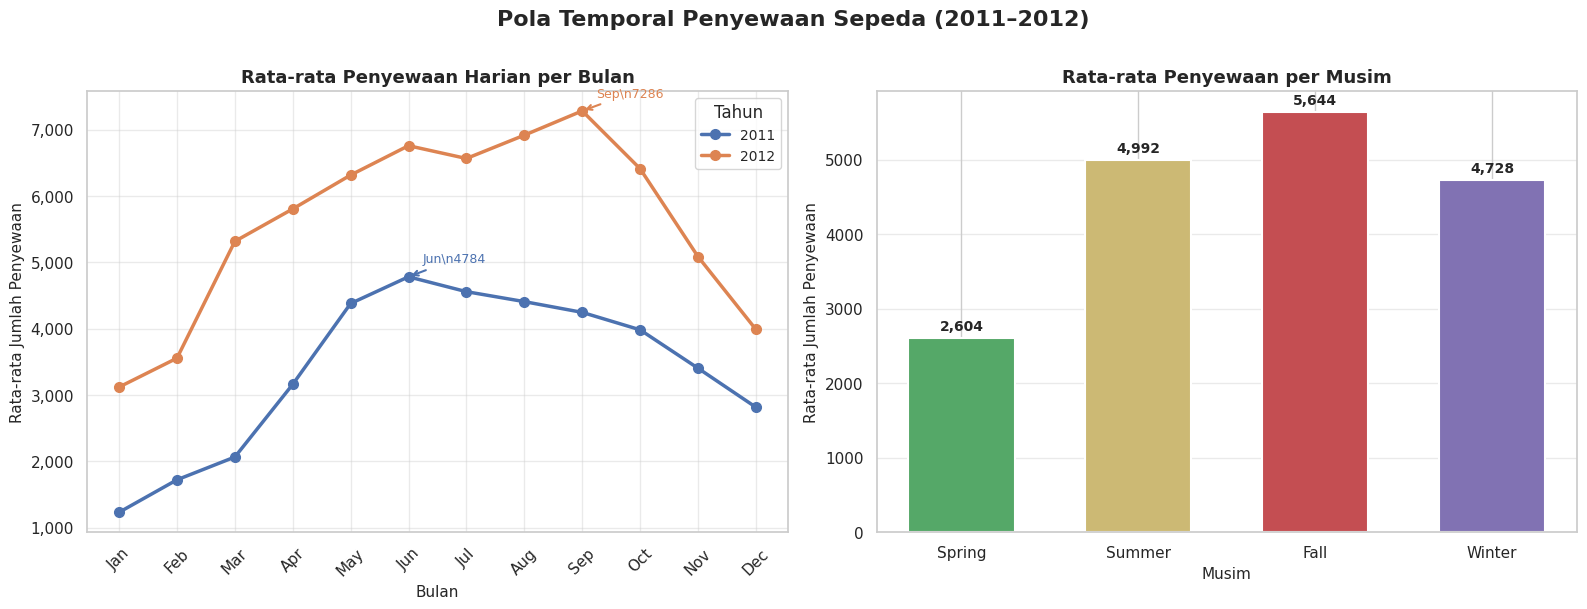

Visualisasi Pertanyaan 1 berhasil disimpan.


In [24]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle(
    'Pola Temporal Penyewaan Sepeda (2011–2012)',
    fontsize=16, fontweight='bold', y=1.01
)

ax1 = axes[0]
month_order = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
monthly_line = (
    day_df.groupby(['yr_label', 'mnth', 'mnth_label'])['cnt']
    .mean()
    .reset_index()
    .sort_values('mnth')
)

colors_yr = {'2011': '#4C72B0', '2012': '#DD8452'}
for yr, grp in monthly_line.groupby('yr_label'):
    ax1.plot(
        grp['mnth_label'], grp['cnt'],
        marker='o', linewidth=2.5, markersize=7,
        color=colors_yr[yr], label=yr
    )

ax1.set_title('Rata-rata Penyewaan Harian per Bulan', fontsize=13, fontweight='bold')
ax1.set_xlabel('Bulan', fontsize=11)
ax1.set_ylabel('Rata-rata Jumlah Penyewaan', fontsize=11)
ax1.set_xticks(range(12))
ax1.set_xticklabels(month_order, rotation=45)
ax1.legend(title='Tahun', fontsize=10)
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
ax1.grid(True, alpha=0.4)

for yr, grp in monthly_line.groupby('yr_label'):
    idx_max = grp['cnt'].idxmax()
    row = grp.loc[idx_max]
    ax1.annotate(
        f"{row['mnth_label']}\\n{row['cnt']:.0f}",
        xy=(list(month_order).index(row['mnth_label']), row['cnt']),
        xytext=(10, 10), textcoords='offset points',
        fontsize=9, color=colors_yr[yr],
        arrowprops=dict(arrowstyle='->', color=colors_yr[yr], lw=1.5)
    )

ax2 = axes[1]
season_data = (
    day_df.groupby('season_label')['cnt']
    .mean()
    .loc[['Spring', 'Summer', 'Fall', 'Winter']]
    .reset_index()
)

palette_season = {
    'Spring': '#55A868',
    'Summer': '#CCB974',
    'Fall'  : '#C44E52',
    'Winter': '#8172B3'
}
bars = ax2.bar(
    season_data['season_label'],
    season_data['cnt'],
    color=[palette_season[s] for s in season_data['season_label']],
    edgecolor='white', linewidth=1.5, width=0.6
)

for bar, val in zip(bars, season_data['cnt']):
    ax2.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 60,
        f'{val:,.0f}',
        ha='center', va='bottom', fontsize=10, fontweight='bold'
    )

ax2.set_title('Rata-rata Penyewaan per Musim', fontsize=13, fontweight='bold')
ax2.set_xlabel('Musim', fontsize=11)
ax2.set_ylabel('Rata-rata Jumlah Penyewaan', fontsize=11)
ax2.grid(True, axis='y', alpha=0.4)

plt.tight_layout()
plt.savefig('plot_temporal_analysis.png', dpi=150, bbox_inches='tight')
plt.show()
print("Visualisasi Pertanyaan 1 berhasil disimpan.")


**Kesimpulan Visualisasi Pertanyaan 1 (Pola Temporal):**

- **Pola Musiman yang Teratur & Berulang:**
  - Grafik garis menunjukkan tren musiman yang sangat konsisten di kedua tahun: penyewaan terendah terjadi di awal tahun (**Januari**), mengalami akselerasi peningkatan signifikan menuju pertengahan tahun, mencapai puncaknya (**Juni pada 2011** dengan 4.784 unit/hari dan **September pada 2012** dengan 7.286 unit/hari), lalu melandai kembali di akhir tahun.

- **Kesenjangan Performa Antar-Musim:**
  - Diagram batang menegaskan bahwa musim **Fall (Gugur)** mencatatkan rata-rata penyewaan tertinggi (**5.644 unit/hari**), disusul oleh musim **Summer (4.992 unit/hari)** dan **Winter (4.728 unit/hari)**.
  - Musim **Spring (Semi)** menjadi musim dengan performa terendah (**2.604 unit/hari**). Rata-rata sewa di musim Fall lebih dari **2,1× lipat (+116,7%)** dibandingkan musim Spring, menuntut perbedaan strategi penempatan armada antar-musim.

- **Pertumbuhan Bisnis yang Konsisten Sepanjang Tahun (*YoY Growth*):**
  - Garis tren tahun 2012 berada **selalu di atas garis tahun 2011 pada setiap bulan** tanpa terkecuali. Hal ini menegaskan pertumbuhan tahunan yang solid sebesar **+64,9%**, membuktikan bahwa peningkatan volume bukan sekadar anomali musiman musiman, melainkan ekspansi pasar yang nyata.

- **Rekomendasi Bisnis:**
  - **Manajemen Siklus Armada:** Jadikan kuartal kedua dan ketiga (Mei–Oktober) sebagai periode *peak capacity* dengan seluruh armada siap jalan dan operasional logistik maksimal. Sebaliknya, gunakan kuartal pertama (Januari–Maret) saat *demand* rendah untuk peremajaan unit dan efisiensi biaya operasional.


### Pertanyaan 2: User Behavior — Pola Per Jam: Hari Kerja vs Non-Kerja

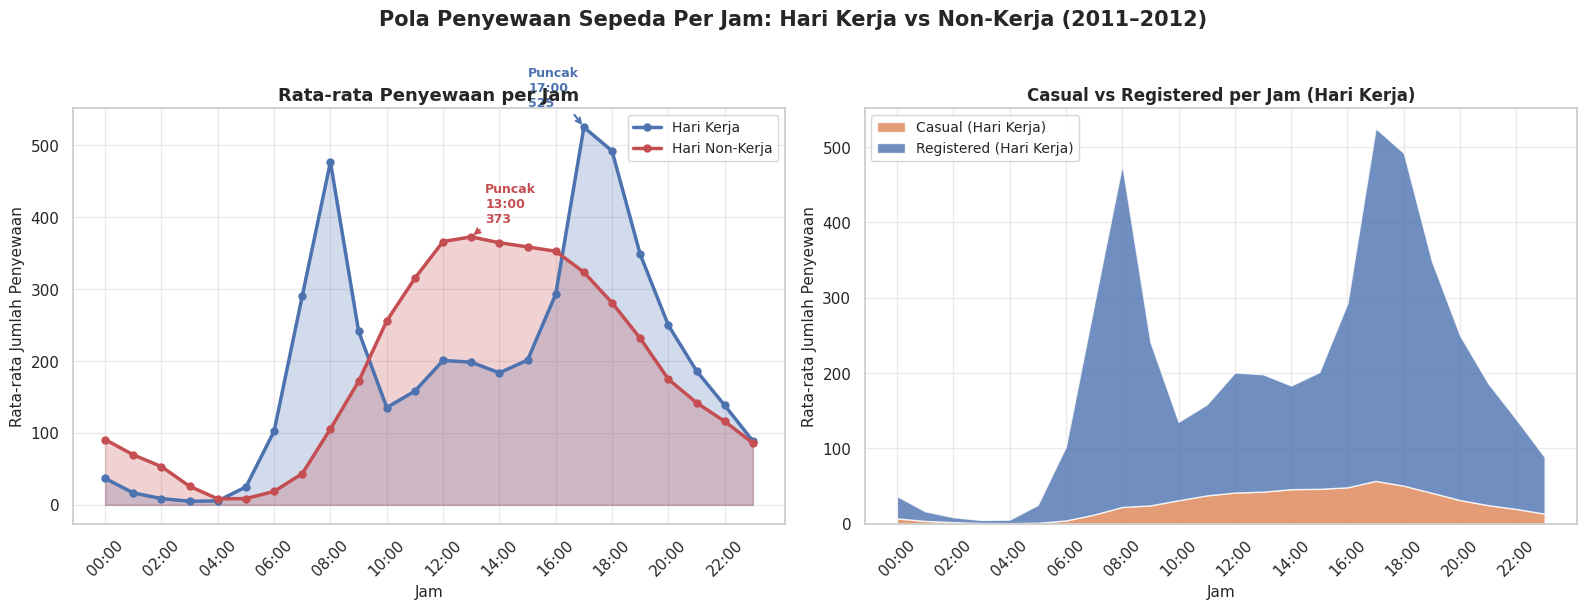

Visualisasi Pertanyaan 2 berhasil disimpan.


In [25]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle(
    'Pola Penyewaan Sepeda Per Jam: Hari Kerja vs Non-Kerja (2011–2012)',
    fontsize=15, fontweight='bold', y=1.01
)

ax1 = axes[0]
hourly_grp = (
    hour_df.groupby(['hr', 'workingday_label'])['cnt']
    .mean()
    .reset_index()
)

work_data   = hourly_grp[hourly_grp['workingday_label'] == 'Yes']
nowrk_data  = hourly_grp[hourly_grp['workingday_label'] == 'No']

ax1.fill_between(work_data['hr'], work_data['cnt'], alpha=0.25, color='#4C72B0')
ax1.fill_between(nowrk_data['hr'], nowrk_data['cnt'], alpha=0.25, color='#C44E52')
ax1.plot(work_data['hr'], work_data['cnt'], color='#4C72B0', linewidth=2.5,
         marker='o', markersize=5, label='Hari Kerja')
ax1.plot(nowrk_data['hr'], nowrk_data['cnt'], color='#C44E52', linewidth=2.5,
         marker='o', markersize=5, label='Hari Non-Kerja')

pk_work  = work_data.loc[work_data['cnt'].idxmax()]
pk_nowrk = nowrk_data.loc[nowrk_data['cnt'].idxmax()]

ax1.annotate(
    f"Puncak\n{pk_work['hr']:02d}:00\n{pk_work['cnt']:.0f}",
    xy=(pk_work['hr'], pk_work['cnt']),
    xytext=(-40, 15), textcoords='offset points',
    fontsize=9, color='#4C72B0', fontweight='bold',
    arrowprops=dict(arrowstyle='->', color='#4C72B0', lw=1.5)
)
ax1.annotate(
    f"Puncak\n{pk_nowrk['hr']:02d}:00\n{pk_nowrk['cnt']:.0f}",
    xy=(pk_nowrk['hr'], pk_nowrk['cnt']),
    xytext=(10, 10), textcoords='offset points',
    fontsize=9, color='#C44E52', fontweight='bold',
    arrowprops=dict(arrowstyle='->', color='#C44E52', lw=1.5)
)

ax1.set_title('Rata-rata Penyewaan per Jam', fontsize=13, fontweight='bold')
ax1.set_xlabel('Jam', fontsize=11)
ax1.set_ylabel('Rata-rata Jumlah Penyewaan', fontsize=11)
ax1.set_xticks(range(0, 24, 2))
ax1.set_xticklabels([f'{h:02d}:00' for h in range(0, 24, 2)], rotation=45)
ax1.legend(fontsize=10)
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
ax1.grid(True, alpha=0.4)

ax2 = axes[1]
user_hr_work = (
    hour_df[hour_df['workingday_label'] == 'Yes']
    .groupby('hr')[['casual', 'registered']]
    .mean()
)
user_hr_nowrk = (
    hour_df[hour_df['workingday_label'] == 'No']
    .groupby('hr')[['casual', 'registered']]
    .mean()
)

hrs = user_hr_work.index
ax2.stackplot(
    hrs,
    user_hr_work['casual'],
    user_hr_work['registered'],
    labels=['Casual (Hari Kerja)', 'Registered (Hari Kerja)'],
    colors=['#DD8452', '#4C72B0'],
    alpha=0.8
)

ax2.set_title('Casual vs Registered per Jam (Hari Kerja)', fontsize=12, fontweight='bold')
ax2.set_xlabel('Jam', fontsize=11)
ax2.set_ylabel('Rata-rata Jumlah Penyewaan', fontsize=11)
ax2.set_xticks(range(0, 24, 2))
ax2.set_xticklabels([f'{h:02d}:00' for h in range(0, 24, 2)], rotation=45)
ax2.legend(fontsize=10, loc='upper left')
ax2.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
ax2.grid(True, alpha=0.4)

plt.tight_layout()
plt.savefig('plot_user_behavior.png', dpi=150, bbox_inches='tight')
plt.show()
print("Visualisasi Pertanyaan 2 berhasil disimpan.")

**Kesimpulan Visualisasi Pertanyaan 2 (Perilaku Per Jam):**



- **Dua Profil Kurva yang Sangat Berbeda (*Bimodal* vs *Unimodal*):**
  - **Hari Kerja (Garis Biru):** Membentuk kurva **bimodal (dua puncak tajam)** khas pola komuter:
    - Puncak pagi pada **08:00** (~477 unit/jam) saat jam berangkat kerja.
    - Puncak sore pada **17:00 (puncak tertinggi: 525 unit/jam)** dan **18:00** (~492 unit/jam) saat jam pulang kerja.
  - **Hari Non-Kerja (Garis Merah):** Membentuk kurva **unimodal (satu puncak kubah)** khas aktivitas santai/rekreasi:
    - Mencapai puncak pada pukul **13:00 (373 unit/jam)** dan bertahan stabil di level tinggi sepanjang pukul 11:00–16:00.

- **Pendorong Lonjakan Komuter Adalah Pengguna Terdaftar (*Registered*):**
  - Grafik area di sebelah kanan memperlihatkan secara jelas bahwa **dua lonjakan tajam pada hari kerja hampir seluruhnya digerakkan oleh pengguna *Registered***.
  - Pengguna *Casual* pada hari kerja memiliki pola yang relatif datar dengan volume rendah (hanya sedikit naik di siang hingga sore hari), membuktikan bahwa pengguna kasual bukan pengguna komuter harian.

- **Karakteristik Penggunaan di Luar Jam Sibuk:**
  - Pada rentang waktu tengah hari (10:00–15:00), tingkat penyewaan pada hari non-kerja justru jauh melampaui hari kerja (selisih hingga ~170 unit/jam pada pukul 13:00), menunjukkan pergeseran fungsi sepeda dari alat transportasi wajib menjadi sarana rekreasi.

- **Rekomendasi Bisnis & Operasional:**
  - **Penjadwalan Redistribusi Armada (*Dynamic Rebalancing*):**
    - *Hari Kerja:* Wajib melakukan penyeimbangan unit sebelum pukul **07:30** (memasok stasiun pemukiman/stasiun kereta) dan sebelum pukul **16:30** (memasok stasiun kawasan perkantoran).
    - *Akhir Pekan:* Fokuskan penumpukan unit di area publik, taman, dan destinasi rekreasi mulai pukul **10:00**.
  - **Segmentasi Pemasaran:** Manfaatkan pengguna kasual di akhir pekan sebagai target empuk program konversi menjadi pelanggan terdaftar (*membership/subscription*) melalui kampanye in-app saat mereka selesai bersepeda.



### Pertanyaan 3: Weather Impact — Pengaruh Cuaca terhadap Penyewaan

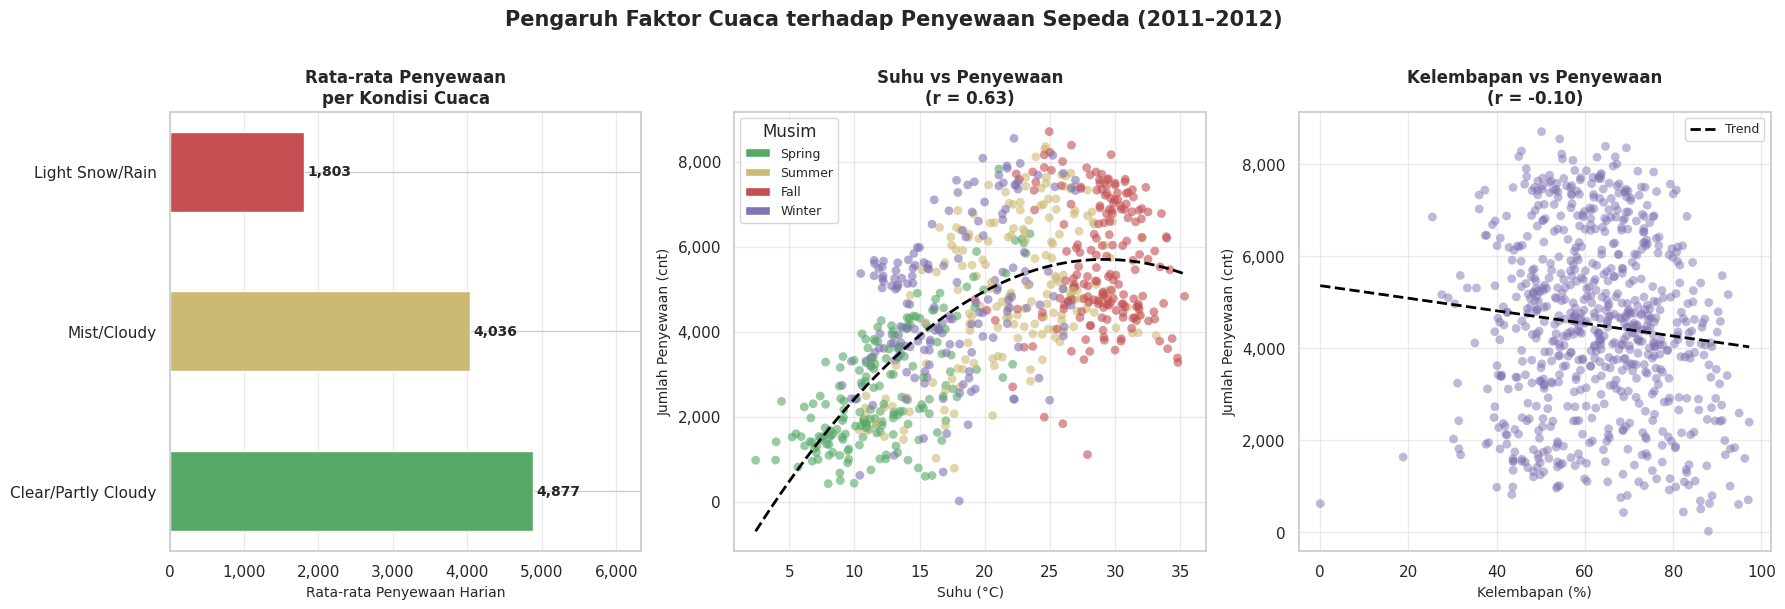

Visualisasi Pertanyaan 3 berhasil disimpan.


In [26]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle(
    'Pengaruh Faktor Cuaca terhadap Penyewaan Sepeda (2011–2012)',
    fontsize=15, fontweight='bold', y=1.01
)

ax1 = axes[0]
weather_order = ['Clear/Partly Cloudy', 'Mist/Cloudy', 'Light Snow/Rain']
weather_avg_plot = (
    day_df[day_df['weather_label'].isin(weather_order)]
    .groupby('weather_label')['cnt']
    .mean()
    .loc[weather_order]
)

colors_w = ['#55A868', '#CCB974', '#C44E52']
bars = ax1.barh(weather_order, weather_avg_plot.values, color=colors_w,
                edgecolor='white', linewidth=1, height=0.5)

for bar, val in zip(bars, weather_avg_plot.values):
    ax1.text(val + 50, bar.get_y() + bar.get_height()/2,
             f'{val:,.0f}', va='center', fontsize=10, fontweight='bold')

ax1.set_title('Rata-rata Penyewaan\nper Kondisi Cuaca', fontsize=12, fontweight='bold')
ax1.set_xlabel('Rata-rata Penyewaan Harian', fontsize=10)
ax1.set_xlim(0, weather_avg_plot.max() * 1.3)
ax1.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
ax1.grid(True, axis='x', alpha=0.4)

ax2 = axes[1]
scatter_colors = day_df['season_label'].map(
    {'Spring': '#55A868', 'Summer': '#CCB974', 'Fall': '#C44E52', 'Winter': '#8172B3'}
)

sc = ax2.scatter(
    day_df['temp_celsius'], day_df['cnt'],
    c=scatter_colors, alpha=0.6, s=40, edgecolors='none'
)

z = np.polyfit(day_df['temp_celsius'], day_df['cnt'], 2)
p = np.poly1d(z)
x_line = np.linspace(day_df['temp_celsius'].min(), day_df['temp_celsius'].max(), 100)
ax2.plot(x_line, p(x_line), color='black', linewidth=2, linestyle='--', label='Trend')

from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#55A868', label='Spring'),
    Patch(facecolor='#CCB974', label='Summer'),
    Patch(facecolor='#C44E52', label='Fall'),
    Patch(facecolor='#8172B3', label='Winter'),
]
ax2.legend(handles=legend_elements, fontsize=9, title='Musim')

corr_temp = day_df['temp_celsius'].corr(day_df['cnt'])
ax2.set_title(f'Suhu vs Penyewaan\n(r = {corr_temp:.2f})', fontsize=12, fontweight='bold')
ax2.set_xlabel('Suhu (°C)', fontsize=10)
ax2.set_ylabel('Jumlah Penyewaan (cnt)', fontsize=10)
ax2.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
ax2.grid(True, alpha=0.4)

ax3 = axes[2]
ax3.scatter(
    day_df['hum_pct'], day_df['cnt'],
    alpha=0.5, s=40, color='#8172B3', edgecolors='none'
)

z2 = np.polyfit(day_df['hum_pct'], day_df['cnt'], 1)
p2 = np.poly1d(z2)
x_line2 = np.linspace(day_df['hum_pct'].min(), day_df['hum_pct'].max(), 100)
ax3.plot(x_line2, p2(x_line2), color='black', linewidth=2, linestyle='--', label='Trend')
ax3.legend(fontsize=9)

corr_hum = day_df['hum_pct'].corr(day_df['cnt'])
ax3.set_title(f'Kelembapan vs Penyewaan\n(r = {corr_hum:.2f})', fontsize=12, fontweight='bold')
ax3.set_xlabel('Kelembapan (%)', fontsize=10)
ax3.set_ylabel('Jumlah Penyewaan (cnt)', fontsize=10)
ax3.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
ax3.grid(True, alpha=0.4)

plt.tight_layout()
plt.savefig('plot_weather_impact.png', dpi=150, bbox_inches='tight')
plt.show()
print("Visualisasi Pertanyaan 3 berhasil disimpan.")

**Kesimpulan Visualisasi Pertanyaan 3 (Pengaruh Cuaca):**



- **Dampak Drastis Kondisi Cuaca terhadap Volume Harian:**
  - Grafik batang di sebelah kiri menunjukkan hubungan linear negatif yang tegas terhadap keparahan cuaca:
    - Cuaca cerah/sedikit berawan (**Clear/Partly Cloudy**) memimpin dengan rata-rata tertinggi sebesar **4.877 sepeda/hari**.
    - Cuaca berkabut (**Mist/Cloudy**) menghasilkan rata-rata **4.036 sepeda/hari** (turun ~17,2%).
    - Cuaca hujan/salju (**Light Snow/Rain**) anjlok drastis ke angka **1.803 sepeda/hari** — terjadi penurunan masif sebesar **~63,0%** dibandingkan kondisi cerah.

- **Suhu Memiliki Pola Kurva Non-Linear (*Inverted U-Shape*):**
  - Grafik sebaran tengah membuktikan korelasi positif kuat (**r = 0,63**) antara suhu dan penyewaan, dengan garis tren berbentuk lengkungan kuadratik:
    - Permintaan meningkat sangat tajam dari suhu dingin (<10°C) menuju zona hangat.
    - Titik puncak (*sweet spot*) tercapai pada rentang **20–30°C** (terkonsentrasi pada musim Summer dan Fall).
    - Memasuki suhu panas ekstrem (**>30–35°C**), garis tren mulai melandai dan sedikit berbelok turun, mengindikasikan rasa tidak nyaman pengguna saat bersepeda di bawah terik berlebih.

- **Kelembapan Berpengaruh Negatif namun Bersifat Lemah:**
  - Grafik sebaran kanan menunjukkan korelasi negatif yang sangat lemah (**r = -0,10**).
  - Garis tren linier hanya mengalami sedikit kemiringan ke bawah seiring naiknya kelembapan, menandakan bahwa kelembapan udara bukanlah faktor penghambat utama selama tidak disertai hujan.

- **Rekomendasi Bisnis & Operasional:**
  - **Manajemen Operasional Berbasis Cuaca (*Weather-Triggered Operations*):**
    - **Hari Cerah & Hangat (20–30°C):** Kerahkan kapasitas armada 100% dan tingkatkan frekuensi sirkulasi kendaraan logistik penyeimbang (*rebalancing van*).
    - **Hari Hujan/Salju:** Batasi perpindahan armada di lapangan guna efisiensi bahan bakar dan keselamatan staf lapangan. Manfaatkan hari bersuhu buruk untuk menarik sepeda yang membutuhkan reparasi (*maintenance pull*).
  - **Pemasaran Dinamis:** Aktifkan promosi khusus (misal: diskon proteksi cuaca atau gratis menit pertama) saat cuaca mendung/lembab guna menahan penurunan permintaan harian.



## Analisis Lanjutan: Clustering Hari Berdasarkan Profil Penyewaan

Pada bagian ini, kita akan menerapkan teknik **clustering manual (binning)** untuk mengelompokkan hari-hari ke dalam segmen berdasarkan kombinasi karakteristik berikut:
- **Jumlah penyewaan harian (cnt)** → tingkatan permintaan
- **Kondisi cuaca** → favorabilitas lingkungan
- **Tipe hari** (working day vs non-working day)

Tujuannya adalah memahami profil hari dengan permintaan tinggi vs rendah untuk membantu pengambilan keputusan operasional.

In [27]:

print("Distribusi cnt (day_df):")
print(day_df['cnt'].describe())
print()

day_df['demand_tier'] = pd.cut(
    day_df['cnt'],
    bins=[0, 2000, 3500, 5500, 10000],
    labels=['Low Demand\n(<2000)', 'Medium Demand\n(2000-3500)',
            'High Demand\n(3500-5500)', 'Very High Demand\n(>5500)']
)

tier_summary = (
    day_df.groupby('demand_tier', observed=True)
    .agg(
        jumlah_hari=('cnt', 'count'),
        avg_cnt=('cnt', 'mean'),
        avg_temp=('temp_celsius', 'mean'),
        avg_hum=('hum_pct', 'mean'),
        pct_workday=('workingday', 'mean'),
        pct_good_weather=('weathersit', lambda x: (x == 1).mean())
    )
    .round(2)
)

tier_summary['pct_workday'] = (tier_summary['pct_workday'] * 100).round(1).astype(str) + '%'
tier_summary['pct_good_weather'] = (tier_summary['pct_good_weather'] * 100).round(1).astype(str) + '%'

print("=" * 70)
print("PROFIL SEGMEN PERMINTAAN PENYEWAAN SEPEDA")
print("=" * 70)
print(tier_summary.to_string())

Distribusi cnt (day_df):
count     731.000000
mean     4504.348837
std      1937.211452
min        22.000000
25%      3152.000000
50%      4548.000000
75%      5956.000000
max      8714.000000
Name: cnt, dtype: float64

PROFIL SEGMEN PERMINTAAN PENYEWAAN SEPEDA
                            jumlah_hari  avg_cnt  avg_temp  avg_hum pct_workday pct_good_weather
demand_tier                                                                                     
Low Demand\n(<2000)                  98  1394.78     11.08    63.14       61.0%            45.0%
Medium Demand\n(2000-3500)          121  2784.96     14.92    62.95       61.0%            54.0%
High Demand\n(3500-5500)            289  4505.07     22.27    64.23       72.0%            64.0%
Very High Demand\n(>5500)           223  6802.89     24.75    60.69       70.0%            76.0%


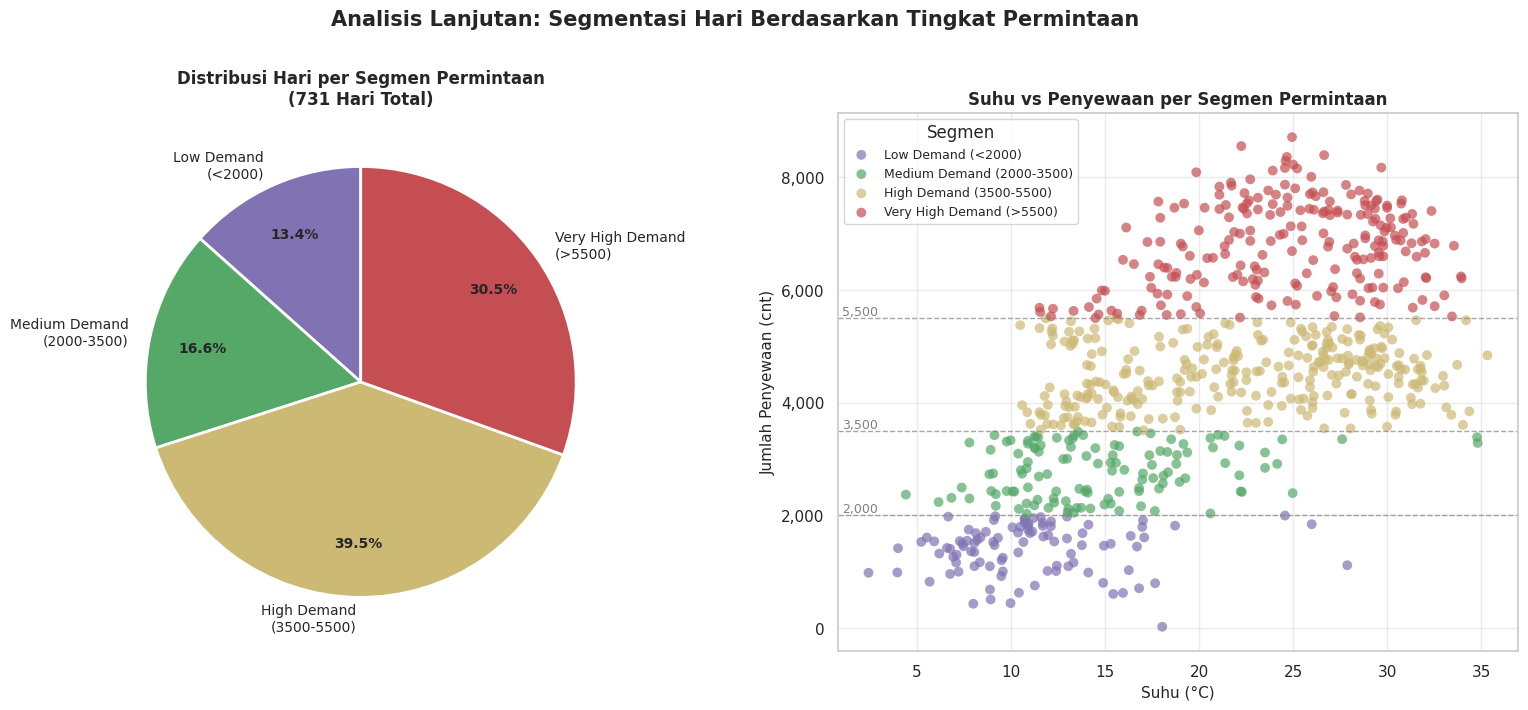

Visualisasi Analisis Lanjutan berhasil disimpan.


In [28]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
fig.suptitle(
    'Analisis Lanjutan: Segmentasi Hari Berdasarkan Tingkat Permintaan',
    fontsize=15, fontweight='bold', y=1.01
)

tier_colors = {
    'Low Demand\n(<2000)'       : '#8172B3',
    'Medium Demand\n(2000-3500)': '#55A868',
    'High Demand\n(3500-5500)'  : '#CCB974',
    'Very High Demand\n(>5500)' : '#C44E52'
}

ax1 = axes[0]
tier_counts = day_df['demand_tier'].value_counts().sort_index()

wedge_colors = [tier_colors[t] for t in tier_counts.index]
wedges, texts, autotexts = ax1.pie(
    tier_counts.values,
    labels=[t.replace('\n', '\n') for t in tier_counts.index],
    colors=wedge_colors,
    autopct='%1.1f%%',
    startangle=90,
    pctdistance=0.75,
    wedgeprops=dict(edgecolor='white', linewidth=2)
)
for text in texts:
    text.set_fontsize(10)
for autotext in autotexts:
    autotext.set_fontsize(10)
    autotext.set_fontweight('bold')

ax1.set_title('Distribusi Hari per Segmen Permintaan\n(731 Hari Total)', fontsize=12, fontweight='bold')

ax2 = axes[1]
for tier_name, grp in day_df.groupby('demand_tier', observed=True):
    ax2.scatter(
        grp['temp_celsius'], grp['cnt'],
        label=tier_name.replace('\n', ' '),
        color=tier_colors[tier_name],
        alpha=0.7, s=50, edgecolors='none'
    )

for boundary in [2000, 3500, 5500]:
    ax2.axhline(boundary, color='gray', linestyle='--', linewidth=1, alpha=0.7)
    ax2.text(1, boundary + 50, f'{boundary:,}', fontsize=9, color='gray')

ax2.set_title('Suhu vs Penyewaan per Segmen Permintaan', fontsize=12, fontweight='bold')
ax2.set_xlabel('Suhu (°C)', fontsize=11)
ax2.set_ylabel('Jumlah Penyewaan (cnt)', fontsize=11)
ax2.legend(fontsize=9, title='Segmen', loc='upper left')
ax2.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
ax2.grid(True, alpha=0.4)

plt.tight_layout()
plt.savefig('plot_clustering.png', dpi=150, bbox_inches='tight')
plt.show()
print("Visualisasi Analisis Lanjutan berhasil disimpan.")

Distribusi Segmen Permintaan per Musim (%)
demand_tier   Low Demand\n(<2000)  Medium Demand\n(2000-3500)  High Demand\n(3500-5500)  Very High Demand\n(>5500)
season_label                                                                                                      
Spring                       43.6                        32.0                      20.4                        3.9
Summer                        4.9                        15.2                      40.2                       39.7
Fall                          1.6                         2.1                      47.9                       48.4
Winter                        3.9                        17.4                      49.4                       29.2


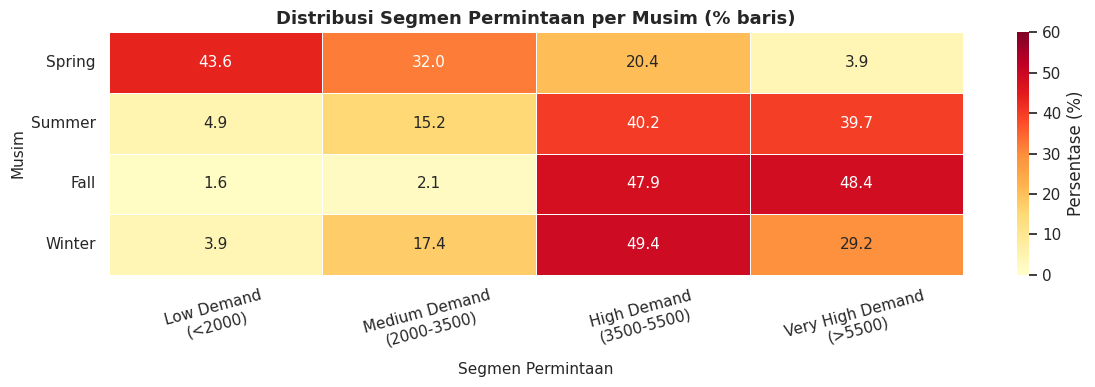

In [29]:
seg_season = pd.crosstab(
    day_df['season_label'],
    day_df['demand_tier'],
    normalize='index'
).round(3) * 100

seg_season = seg_season.loc[['Spring', 'Summer', 'Fall', 'Winter']]

print("=" * 70)
print("Distribusi Segmen Permintaan per Musim (%)")
print("=" * 70)
print(seg_season.to_string())

fig, ax = plt.subplots(figsize=(12, 4))
sns.heatmap(
    seg_season, annot=True, fmt='.1f', cmap='YlOrRd',
    linewidths=0.5, ax=ax, cbar_kws={'label': 'Persentase (%)'},
    vmin=0, vmax=60
)
ax.set_title('Distribusi Segmen Permintaan per Musim (% baris)', fontsize=13, fontweight='bold')
ax.set_xlabel('Segmen Permintaan', fontsize=11)
ax.set_ylabel('Musim', fontsize=11)
ax.tick_params(axis='x', rotation=15)
ax.tick_params(axis='y', rotation=0)
plt.tight_layout()
plt.savefig('plot_heatmap_season_tier.png', dpi=150, bbox_inches='tight')
plt.show()

**Insight Analisis Lanjutan (Clustering Manual / Binning):**



- **Distribusi Segmen Permintaan (Total 731 Hari):**
  - **Low Demand (<2.000 sewa):** Mencakup **13,4%** (98 hari). Rata-rata sewa hanya **1.395 sepeda/hari** dengan karakteristik suhu dingin (rata-rata **11,1°C**) dan probabilitas cuaca baik terendah (**45,0%**).
  - **Medium Demand (2.000–3.500 sewa):** Mencakup **16,6%** (121 hari) dengan rata-rata **2.785 sepeda/hari** pada suhu rata-rata 14,9°C.
  - **High Demand (3.500–5.500 sewa):** Segmen **terbesar** yang mencakup **39,5%** (289 hari) dengan rata-rata **4.505 sepeda/hari**.
  - **Very High Demand (>5.500 sewa):** Mencakup **30,5%** (223 hari) dengan rata-rata **6.803 sepeda/hari**. Terjadi pada suhu optimal rata-rata **24,8°C**, cuaca baik mencapai **76,0%**, dan 70% terjadi pada hari kerja (*working day*).
  - *Secara kumulatif, sebanyak **70,0% hari operasional** (High + Very High) berada pada level permintaan tinggi hingga sangat tinggi.*

- **Pola Dominasi Segmen per Musim (Berdasarkan Heatmap):**
  - **Musim Spring (Semi) — Terkonsentrasi di Demand Rendah:**
    - Sebanyak **43,6% hari di musim Spring tergolong *Low Demand*** dan 32,0% tergolong *Medium Demand*. 
    - Hanya **3,9%** hari di musim ini yang berhasil mencapai *Very High Demand*, menjadikannya musim paling sepi penyewa.
  - **Musim Fall (Gugur) — Didominasi Mutlak oleh Demand Tinggi:**
    - Sebanyak **48,4% hari berada di tier *Very High Demand*** dan **47,9% berada di tier *High Demand*** (total **96,3%** hari berada di level tinggi). Hari dengan *Low Demand* hampir tidak ada (hanya 1,6%).
  - **Musim Summer & Winter:**
    - Musim **Summer** memiliki porsi *Very High Demand* sebesar **39,7%** dan *High Demand* sebesar **40,2%**.
    - Musim **Winter** tetap mencatatkan performa solid dengan **49,4%** di kategori *High Demand*, mematahkan asumsi bahwa musim dingin selalu lesu.

- **Korelasi Profil Lingkungan & Hari Kerja:**
  - Hari dengan tingkat permintaan tinggi (High & Very High) memiliki kesamaan karakteristik: persentase hari kerja yang tinggi (**70%–72%**), cuaca cerah/kondusif (**64%–76%**), dan rentang suhu nyaman (**22°C–25°C**).

- **Implikasi Bisnis & Playbook Operasional (Actionable SOP):**
  - **Tier 1: SOP Siaga Maksimum (*Very High Demand Days*):** Berlaku saat prakiraan cuaca menunjukkan suhu >22°C di musim Summer/Fall pada hari kerja. Kerahkan 100% armada sepeda, batalkan cuti tim redistribusi lapangan, dan siagakan suku cadang cepat di stasiun tersibuk.
  - **Tier 2: SOP Pemeliharaan Berkala (*Low Demand Days*):** Berlaku saat musim Spring atau saat suhu dingin (<10°C) disertai hujan. Tarik sepeda yang mengalami kendala teknis minor ke bengkel pusat untuk diservis besar tanpa khawatir kekurangan unit di stasiun.
  - **Optimalisasi Staf Lapangan:** Alokasikan jam lembur pengemudi mobil penyeimbang (*rebalancing driver*) hanya pada hari yang diprediksi masuk ke dalam tier *High* dan *Very High Demand*.



## Conclusion & Recommendation

### Kesimpulan

**Kesimpulan Pertanyaan 1 (Temporal Analysis):**
Penyewaan sepeda menunjukkan **pola musiman yang konsisten dan berulang** sepanjang tahun 2011–2012. Tingkat penyewaan tertinggi terjadi pada **musim Fall (Gugur)** dengan rata-rata **5.644 sepeda/hari**, dengan puncak bulanan tercatat pada **Juni 2011 (4.784 sepeda/hari)** dan **September 2012 (7.286 sepeda/hari)**. Sebaliknya, penyewaan terendah terjadi pada **musim Spring (Semi)** dengan rata-rata **2.604 sepeda/hari**, di mana bulan **Januari** konsisten menjadi titik nadir permintaan tahunan. Secara keseluruhan, bisnis bertumbuh pesat dan sehat dengan lonjakan volume tahunan sebesar **+64,9%** dari 2011 (1,24 juta transaksi) ke 2012 (2,05 juta transaksi).

---

**Kesimpulan Pertanyaan 2 (User Behavior Analysis):**
Perilaku pengguna per jam terbagi secara kontras berdasarkan tipe hari:
- **Hari Kerja (*Bimodal*):** Terbentuk dua puncak jam sibuk komuter yang sangat tajam, yaitu pagi hari pukul **08:00 (477 unit/jam)** saat berangkat kerja dan sore hari pukul **17:00 (puncak harian: 525 unit/jam)** serta **18:00 (492 unit/jam)** saat pulang kerja. Lonjakan ini didominasi mutlak oleh pengguna terdaftar (**Registered: 86,7%**).
- **Hari Non-Kerja (*Unimodal*):** Aktivitas bergeser ke fungsi rekreasi di tengah hari, memuncak pada pukul **13:00 (373 unit/jam)** dan aktif stabil antara pukul 11:00–16:00. Porsi pengguna kasual (**Casual**) melonjak drastis hingga **31,6%** (naik lebih dari 2× lipat dibanding hari kerja).

---

**Kesimpulan Pertanyaan 3 (Weather Impact Analysis):**
Kondisi lingkungan dan cuaca bertindak sebagai pendorong (*driver*) sekaligus pembatas utama permintaan:
- **Kondisi Cuaca:** Hari cerah (**Clear/Partly Cloudy**) membukukan permintaan tertinggi (**4.877 sepeda/hari**). Sementara hari hujan/salju (**Light Snow/Rain**) memangkas permintaan hingga tersisa **1.803 sepeda/hari** (penurunan drastis sebesar **~63,0%**).
- **Variabel Suhu & Angin:** Suhu memiliki korelasi positif kuat (**r = +0,63**) dengan pola kurva lengkung; zona kenyamanan (*sweet spot*) bersepeda berada di rentang **20–30°C** (puncak sewa 5.726 sepeda/hari pada rentang 25–30°C), lalu mulai sedikit menurun jika suhu melewati 30°C. Kecepatan angin memiliki korelasi negatif moderat (**r = -0,235**), sedangkan kelembapan berkorelasi negatif lemah (**r = -0,101**).

---

**Kesimpulan Analisis Lanjutan (Clustering Permintaan Harian):**
Segmentasi berbasis *manual binning* mengelompokkan 731 hari ke dalam 4 tingkatan permintaan yang komprehensif:
1. **Low Demand (<2.000 sewa):** Mencakup **13,4% hari** (rata-rata 1.395 sewa/hari). Terkonsentrasi pada musim Spring (**43,6% hari Spring masuk kategori ini**) akibat suhu dingin (rata-rata 11,1°C) dan cuaca buruk.
2. **Medium Demand (2.000–3.500 sewa):** Mencakup **16,6% hari** (rata-rata 2.785 sewa/hari).
3. **High Demand (3.500–5.500 sewa):** Menjadi segmen **terbesar** mencakup **39,5% hari** (rata-rata 4.505 sewa/hari).
4. **Very High Demand (>5.500 sewa):** Mencakup **30,5% hari** (rata-rata 6.803 sewa/hari). Sebanyak **48,4% hari di musim Fall** berada di tier ini, didorong oleh suhu hangat (~24,8°C), probabilitas cuaca baik mencapai 76%, dan mayoritas terjadi pada hari kerja (70%).
- *Secara kumulatif, sebesar **70,0% hari operasional** berada di level permintaan tinggi hingga sangat tinggi (High + Very High Demand).*